# PesaPulse: Expense Category Classifier
**Project Deliverable 2 (CAT 2) · Base model: Logistic Regression**

Group members and who did which section:
Phillip Mwengi 165056 -Problem, data and cleaning

Wilson Mutua 184179-EDA and features

Emmanuel Kiprotich 189802-Modelling, validation and the app demo

## What problem are we solving?
PesaPulse reads a user's past M-Pesa SMS messages and turns them into an expense tracker. An M-Pesa SMS tells us *how much* was spent and *to whom*, but not *what kind* of spending it was. The ML engine fills that gap:

> **Input:** one M-Pesa message (merchant name, amount, time, type of transaction)
> **Output:** the spending category, e.g. Food & Groceries, Transport, Rent & Housing

This is a **supervised, multi-class classification** problem: we train on messages where the category is known, then predict the category of new messages.

## Notebook map
1. Data source
2. Data cleaning: from raw SMS to the final modelling dataset
3. Exploratory data analysis (EDA) with 5 observations
4. Base model: Logistic Regression (baseline, cross-validation, regularisation, evaluation)
5. Further validation (Question 4)
6. What the app will do with a brand-new SMS
7. Limitations and next steps

In [ ]:
import re, string, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold, GridSearchCV, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

SEED = 42   # fixed seed so everyone gets the same results when they re-run the notebook
Path("data").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)

## 1. Data source

The real PesaPulse app pulls a user's past M-Pesa SMS messages after they connect their number. We cannot use real people's messages for coursework (they are private financial data, and the app is not live yet), so we **generate a synthetic dataset that copies the real M-Pesa SMS wording**. Names, phone numbers, amounts and transaction codes are all made up.

The generator also adds the kind of mess real SMS exports contain, so the cleaning section has real work to do:
- promotional / non-transaction messages
- the same message imported twice
- truncated (cut-off) messages
- inconsistent merchant spellings (`NAIVAS SUPERMARKET`, `Naivas Supermarket`, `NAIVAS SUPERMARKET LTD`)
- small shops with unknown names (`KAMAU BUTCHERY`, `ODHIAMBO ENTERPRISES`)
- a few wrong or missing category labels (users mislabel things, or never label them)

**How the labels work in the real app:** a message has no category in it. In production, the label comes from the user confirming or correcting the app's suggestion. Here, the generator assigns it.

If `data/raw_mpesa_sms.csv` already exists, the notebook loads it instead of generating. That is where a real (consented, anonymised) export would go.

In [ ]:
# ---------- Synthetic M-Pesa SMS generator (the only "fake" part of this notebook) ----------
rng = np.random.default_rng(SEED)
def pick(seq):
    return seq[int(rng.integers(len(seq)))]

RAW_PATH = Path("data/raw_mpesa_sms.csv")
N_USERS = 30
START, END = pd.Timestamp("2025-11-01"), pd.Timestamp("2026-10-18 23:59")

FIRST = ["JOHN","MARY","PETER","GRACE","JAMES","FAITH","DAVID","ALICE","SAMUEL","ESTHER","BRIAN","MERCY","KEVIN","LILIAN","DENNIS","ROSE","ANTONY","NANCY","VICTOR","JANE"]
LAST  = ["KAMAU","WANJIRU","OTIENO","AKINYI","MUTUA","KIPROTICH","NJOROGE","ACHIENG","MWANGI","CHEPKOECH","OMONDI","WAFULA","KARIUKI","NYAMBURA","KIPLAGAT","MUTHONI","ODHIAMBO","WAMBUI","KIMANI","JEPTOO"]
AGENTS = ["NAIROBI WEST AGENT","JUJA STAGE AGENT","KAREN MPESA SHOP","RUIRU TOWN AGENT","KILIMANI AGENT"]
def person():
    return f"{pick(FIRST)} {pick(LAST)}"

# category -> weight (events per user per month), amount shape, and which kind of M-Pesa payment it uses
CATS = {
 "Food & Groceries":      dict(w=14,  amt=(600, 0.8, 50, 8000),     kinds={"buy_goods": (1.0, ["NAIVAS SUPERMARKET","QUICKMART LTD","CARREFOUR KENYA","CHANDARANA FOODPLUS","JAVA HOUSE","KFC WESTGATE","GALITOS LTD","ARTCAFFE","CHICKEN INN","FRESH MART BUTCHERY"])}),
 "Transport":             dict(w=10,  amt=(350, 0.9, 30, 6000),     kinds={"buy_goods": (0.7, ["SHELL KAREN","TOTAL ENERGIES RUIRU","RUBIS ENERGY JUJA","SUPER METRO SACCO","EASY COACH LTD"]),
                                                                    "paybill":   (0.3, ["BOLT KENYA","LITTLE CAB KENYA"])}),
 "Bills & Utilities":     dict(w=3,   amt=(1800, 0.7, 200, 12000),  kinds={"paybill": (1.0, ["KENYA POWER","NAIROBI WATER","ZUKU FIBER","DSTV KENYA","GOTV KENYA"])}),
 "Airtime & Data":        dict(w=6,   amt=(100, 0.8, 10, 2000),     kinds={"airtime": (0.75, ["SAFARICOM AIRTIME"]),
                                                                    "paybill": (0.25, ["SAFARICOM DATA BUNDLES"])}),
 "Rent & Housing":        dict(w=1,   amt=(0, 0, 0, 0),             kinds={"paybill": (1.0, ["KILIMANI APARTMENTS LTD","JUJA ESTATES MGMT","RUIRU HOMES AGENCY","SOUTH B PROPERTIES"])}),
 "Education":             dict(w=0.5, amt=(12000, 0.9, 1000, 80000),kinds={"paybill": (1.0, ["UNIVERSITY FEES COLLECTION","HELB REPAYMENT","BRIGHT STARS SCHOOL","COLLEGE FEES ACCOUNT"])}),
 "Entertainment":         dict(w=3,   amt=(900, 0.8, 100, 8000),    kinds={"buy_goods": (0.7, ["CINEMAX KENYA","PLAYZONE ARCADE","NAIROBI NIGHTS BAR"]),
                                                                    "paybill":   (0.3, ["SHOWMAX KENYA"])}),
 "Health":                dict(w=1.5, amt=(900, 0.9, 100, 25000),   kinds={"buy_goods": (0.8, ["GOODLIFE PHARMACY","HEALTHPLUS PHARMACY","CITY CLINIC LAB","DENTAL CARE CENTRE"]),
                                                                    "paybill":   (0.2, ["SHA CONTRIBUTIONS"])}),
 "Shopping":              dict(w=3,   amt=(2200, 0.9, 200, 30000),  kinds={"buy_goods": (0.75, ["TEXTILE HOUSE LTD","GADGET WORLD","FASHION AVENUE","GREEN HARDWARE","EXPRESSIONS STORE"]),
                                                                    "paybill":   (0.25, ["JUMIA KENYA"])}),
 "Savings & Investments": dict(w=2,   amt=(2000, 0.8, 100, 30000),  kinds={"paybill": (1.0, ["STIMA SACCO","ETHICAL MMF","MSHWARI SAVINGS","CHAMA CONTRIBUTIONS"])}),
 "Personal Transfers":    dict(w=7,   amt=(1000, 1.0, 50, 40000),   kinds={"send_money": (1.0, [None])}),
 "Cash Withdrawal":       dict(w=3,   amt=(2000, 0.8, 200, 30000),  kinds={"withdraw": (1.0, AGENTS)}),
}
# small shops with unknown names: the model must learn from words like BUTCHERY / CHEMIST / HARDWARE
LONG_TAIL = {"BUTCHERY":"Food & Groceries","HOTEL":"Food & Groceries","KIOSK":"Food & Groceries","CHEMIST":"Health",
             "HARDWARE":"Shopping","GENERAL SHOP":"Shopping","SALON":"Shopping","PETROL STATION":"Transport",
             "ENTERPRISES":None,"TRADERS":None}   # None = genuinely ambiguous name, category is random

# approximate M-Pesa fee bands (simplified for simulation)
SEND_TIERS     = [(100,0),(500,7),(1000,13),(1500,23),(2500,33),(3500,53),(5000,57),(7500,78),(10000,90),(15000,100),(20000,105),(250000,108)]
WITHDRAW_TIERS = [(100,11),(2500,29),(3500,52),(5000,69),(7500,87),(10000,115),(15000,167),(20000,185),(35000,197),(50000,278),(250000,279)]
def fee_for(kind, amt):
    tiers = SEND_TIERS if kind == "send_money" else WITHDRAW_TIERS if kind == "withdraw" else None
    if tiers is None:
        return 0.0
    for upper, fee in tiers:
        if amt <= upper:
            return float(fee)
    return float(tiers[-1][1])

def hour_weights(cat, weekend):
    h = np.arange(24)
    w = np.where((h >= 6) & (h <= 22), 1.0, 0.02)
    if cat == "Transport" and not weekend:
        w = w + 4*np.exp(-((h-7.5)**2)/2) + 4*np.exp(-((h-18)**2)/3)        # commute peaks
    elif cat == "Food & Groceries":
        w = w + 2.5*np.exp(-((h-13)**2)/2) + 3.5*np.exp(-((h-19)**2)/3)      # lunch and supper
    elif cat == "Entertainment":
        w = w + 3*np.exp(-((h-20)**2)/4) * (2 if weekend else 1)             # evenings, more on weekends
    elif cat == "Airtime & Data":
        w = w + 2*np.exp(-((h-7)**2)/3) + 2*np.exp(-((h-20)**2)/4)
    return w / w.sum()

def sample_ts(ms, cat):
    if cat == "Rent & Housing":
        day = int(rng.integers(1, 6))                                        # rent: first days of the month
    elif cat == "Bills & Utilities":
        day = int(rng.integers(3, 23))
    elif cat == "Savings & Investments" and rng.random() < 0.7:
        day = int(rng.integers(25, ms.days_in_month + 1))                    # saving after pay day
    else:
        day = int(rng.integers(1, ms.days_in_month + 1))
    d = ms.replace(day=day)
    hour = int(rng.choice(24, p=hour_weights(cat, d.dayofweek >= 5)))
    return d + pd.Timedelta(hours=hour, minutes=int(rng.integers(0, 60)))

def sample_amount(cat, kind):
    if kind == "airtime":
        return float(pick([20, 50, 50, 100, 100, 200, 250, 500, 1000]))
    med, sig, lo, hi = CATS[cat]["amt"]
    x = float(np.clip(rng.lognormal(np.log(med), sig), lo, hi))
    if cat == "Cash Withdrawal":    return float(max(200, np.round(x, -2)))
    if cat == "Personal Transfers": return float(max(50, np.round(x / 50) * 50))
    return float(np.round(x))

def make_events(user):
    ev = []
    mult = {c: float(np.exp(rng.normal(0, 0.4))) for c in CATS}              # every user spends a bit differently
    pays_rent, is_student = rng.random() < 0.7, rng.random() < 0.4
    rent_amt = float(np.round(rng.uniform(6000, 35000), -2))
    rent_to  = pick(CATS["Rent & Housing"]["kinds"]["paybill"][1])
    rent_unit = f"{pick('ABC')}{int(rng.integers(1, 30))}"
    salary = float(np.round(rng.uniform(15000, 90000), -2))
    employer = f"{pick(LAST)} {pick(['LOGISTICS','HOLDINGS','AGENCIES','SOLUTIONS'])} LTD"

    def add(ts, kind, party, amt, cat, acct=None):
        if START <= ts <= END:
            ev.append(dict(ts=ts, kind=kind, party=party, amt=amt, cat=cat, acct=acct))

    for ms in pd.date_range(START, END, freq="MS"):
        # income: salary near month end + a few small transfers received
        pay_day = ms.replace(day=min(28, ms.days_in_month)) + pd.Timedelta(hours=int(rng.integers(9, 16)), minutes=int(rng.integers(0, 60)))
        add(pay_day, "received", employer, salary, "Income")
        for _ in range(int(rng.integers(1, 4))):
            add(sample_ts(ms, "Other"), "received", person(), float(max(50, np.round(rng.lognormal(np.log(1500), 0.8) / 50) * 50)), "Income")
        # spending by category
        for cat, cfg in CATS.items():
            if cat == "Rent & Housing":
                if pays_rent:
                    add(sample_ts(ms, cat), "paybill", rent_to, rent_amt, cat, rent_unit)
                continue
            rate = cfg["w"] * mult[cat]
            if cat == "Education":
                rate = 3.0 if (is_student and ms.month in (1, 5, 9)) else 0.0      # fees only for students, in term-start months
            kinds = list(cfg["kinds"]); kw = np.array([cfg["kinds"][k][0] for k in kinds])
            for _ in range(int(rng.poisson(rate))):
                kind = kinds[int(rng.choice(len(kinds), p=kw / kw.sum()))]
                party = pick(cfg["kinds"][kind][1])
                if kind == "send_money":
                    party = person()
                acct = str(int(rng.integers(10**5, 10**9))) if kind in ("paybill", "withdraw") else None
                add(sample_ts(ms, cat), kind, party, sample_amount(cat, kind), cat, acct)
        # unknown small shops
        for _ in range(int(rng.poisson(6))):
            suffix = pick(list(LONG_TAIL))
            cat = LONG_TAIL[suffix] or pick(["Food & Groceries", "Shopping"])
            add(sample_ts(ms, cat), "buy_goods", f"{pick(LAST)} {suffix}", sample_amount(cat, "buy_goods"), cat)
    return ev

# ----- turning events into real-looking SMS text -----
def ksh(x):      return f"Ksh{x:,.2f}"
def fmt_date(t): return f"{t.day}/{t.month}/{t:%y}"
def fmt_time(t): return f"{t.hour % 12 or 12}:{t.minute:02d} {'AM' if t.hour < 12 else 'PM'}"
def phone():
    p = "07" + "".join(str(int(rng.integers(0, 10))) for _ in range(8))
    return p if rng.random() < 0.8 else p[:4] + "***" + p[-3:]                  # some numbers are masked
def noisy(name):
    r = rng.random()
    if r < 0.05: return name.title()
    if r < 0.08: return name + " LTD"
    if r < 0.10: return name.replace(" ", "  ")
    return name
CHARS = np.array(list(string.ascii_uppercase + string.digits))
def make_code(used):
    while True:
        c = pick("QRST") + "".join(rng.choice(CHARS, 9))
        if c not in used:
            used.add(c); return c

def make_message(code, e, bal, fee):
    d, t, amt, b, f = fmt_date(e["ts"]), fmt_time(e["ts"]), ksh(e["amt"]), ksh(bal), ksh(fee)
    gap = " " if rng.random() < 0.5 else ""
    tail = "Amount you can transact within the day is 499,500.00."
    k = e["kind"]
    if k == "buy_goods":
        return f"{code} Confirmed. {amt} paid to {noisy(e['party'])}. on {d} at {t}.{gap}New M-PESA balance is {b}. Transaction cost, {f}. {tail}"
    if k == "paybill":
        return f"{code} Confirmed. {amt} sent to {noisy(e['party'])} for account {e['acct']} on {d} at {t} New M-PESA balance is {b}. Transaction cost, {f}. {tail}"
    if k == "send_money":
        return f"{code} Confirmed. {amt} sent to {e['party']} {phone()} on {d} at {t}. New M-PESA balance is {b}. Transaction cost, {f}. {tail}"
    if k == "airtime":
        return f"{code} confirmed.You bought {amt} of airtime on {d} at {t}.{gap}New M-PESA balance is {b}. Transaction cost, {f}. {tail}"
    if k == "withdraw":
        return f"{code} Confirmed.on {d} at {t} Withdraw {amt} from {e['acct'][:6]} - {e['party']} New M-PESA balance is {b}. Transaction cost, {f}. {tail}"
    return f"{code} Confirmed.You have received {amt} from {e['party']} {phone()} on {d} at {t}  New M-PESA balance is {b}.  Earn interest daily on Ziidi."

JUNK = ["Dear Customer, you can now enjoy Fuliza M-PESA overdraft. Dial *234# to opt in.",
        "Win big this weekend with Bonga Points. Dial *126# to redeem.",
        "Dear Customer, your M-PESA statement for the last 3 months is ready. Dial *334# to view.",
        "Reminder: keep your M-PESA PIN secret. Never share it with anyone."]

def generate_raw_dataset():
    used, rows = set(), []
    for u in range(N_USERS):
        events = sorted(make_events(u), key=lambda e: e["ts"])
        bal = float(rng.integers(500, 6000))
        for e in events:
            fee = fee_for(e["kind"], e["amt"])
            if e["kind"] == "received":
                bal += e["amt"]
            else:
                need = e["amt"] + fee
                if bal < need:                                                  # user tops up before spending
                    top = float(np.ceil((need - bal + rng.integers(200, 5000)) / 50) * 50)
                    t_ev = dict(ts=e["ts"] - pd.Timedelta(seconds=30), kind="received", party=person(), amt=top, cat="Income", acct=None)
                    bal += top
                    rows.append(dict(user_id=u, sms_body=make_message(make_code(used), t_ev, bal, 0.0), label="Income"))
                bal -= need
            rows.append(dict(user_id=u, sms_body=make_message(make_code(used), e, bal, fee),
                             label="Income" if e["cat"] == "Income" else e["cat"]))
    raw = pd.DataFrame(rows)

    # label noise: users mislabel some things; person-to-person transfers are especially ambiguous
    spend = raw["label"].ne("Income")
    pt = spend & raw["label"].eq("Personal Transfers") & (rng.random(len(raw)) < 0.10)
    raw.loc[pt, "label"] = rng.choice(["Rent & Housing", "Food & Groceries", "Transport", "Shopping"], int(pt.sum()))
    flip = spend & (rng.random(len(raw)) < 0.03)
    raw.loc[flip, "label"] = rng.choice(list(CATS), int(flip.sum()))
    raw.loc[spend & (rng.random(len(raw)) < 0.02), "label"] = np.nan             # never labelled by the user

    # truncated messages (cut off mid-text)
    cut = raw.index[rng.random(len(raw)) < 0.008]
    raw.loc[cut, "sms_body"] = [raw.at[i, "sms_body"][:int(rng.integers(30, 110))] for i in cut]
    # promotional messages
    junk = pd.DataFrame(dict(user_id=rng.integers(0, N_USERS, int(0.03 * len(raw))), sms_body=[pick(JUNK) for _ in range(int(0.03 * len(raw)))], label=np.nan))
    # the same message imported twice
    dups = raw.sample(frac=0.015, random_state=SEED)
    return pd.concat([raw, junk, dups], ignore_index=True)

if RAW_PATH.exists():
    raw = pd.read_csv(RAW_PATH)
    print("Loaded existing file:", RAW_PATH)
else:
    raw = generate_raw_dataset()
    raw.to_csv(RAW_PATH, index=False)
    print("Generated and saved:", RAW_PATH)
print("Shape:", raw.shape)
display(raw.head())

Generated and saved: data/raw_mpesa_sms.csv
Shape: (28121, 3)


,user_id,sms_body,label
0,0,RFMSJZ9HJE Confirmed. Ksh44.00 sent to SAFARICOM DATA BUNDLES LTD for account 21709918 on 1/11/25 at 7:53 AM New M-P...,Airtime & Data
1,0,"SRYIARYMJF Confirmed. Ksh637.00 paid to DENTAL CARE CENTRE. on 3/11/25 at 8:49 AM.New M-PESA balance is Ksh3,579.00....",Health
2,0,"SOANZX99IA Confirmed. Ksh959.00 paid to GALITOS LTD. on 3/11/25 at 6:45 PM.New M-PESA balance is Ksh2,620.00. Transa...",Food & Groceries
3,0,"T1HBWT7USK Confirmed.You have received Ksh17,800.00 from MERCY NYAMBURA 0781***881 on 4/11/25 at 2:16 PM New M-PESA...",Income
4,0,"TC4RVCYYX2 Confirmed. Ksh18,900.00 sent to JUJA ESTATES MGMT for account A3 on 4/11/25 at 2:17 PM New M-PESA balance...",NaN


## 2. Data cleaning: from raw SMS to the modelling dataset

The raw data is just text. Before any model can use it, we need to turn each message into clean, structured columns. The plan, in order:

| Step | What we do | Why |
|---|---|---|
| 2.1 | Explore the raw data | Find the problems before fixing them |
| 2.2 | Drop non-transaction messages | Promos are not spending |
| 2.3 | Parse the text with regular expressions | Pull out code, type, amount, merchant, date, balance, fee |
| 2.4 | Remove duplicates and unparseable (truncated) rows | Duplicates double-count spending; broken rows have no usable fields |
| 2.5 | Fix data types and validate values | Amounts must be numbers, dates real dates |
| 2.6 | Impute missing fees | A few cut-off messages lost the fee |
| 2.7 | Normalise merchant names and remove personal data | One merchant should have one spelling; we do not need people's names or numbers |
| 2.8 | Check outliers (and decide what to do) | Rent and school fees are large but real |
| 2.9 | Separate income from expenses; handle missing labels | The model predicts spending categories only |
| 2.10 | Feature engineering | Give the model useful signals (time, weekday, month position) |

### 2.1 Explore the raw data

In [ ]:
print("Rows, columns:", raw.shape)
print("\nMissing values per column:")
print(raw.isna().sum())
print("\nExact duplicate rows:", raw.duplicated().sum())

looks_like_txn = raw["sms_body"].str.match(r"^[A-Z0-9]{10}\s+[Cc]onfirmed")
print("\nMessages that do NOT look like an M-Pesa transaction:", (~looks_like_txn).sum())
display(raw.loc[~looks_like_txn, "sms_body"].drop_duplicates().head(4).to_frame())

raw["sms_len"] = raw["sms_body"].str.len()
print("\nUnusually short transaction messages (< 110 characters), probably cut off:", ((raw["sms_len"] < 110) & looks_like_txn).sum())
display(raw.loc[(raw["sms_len"] < 110) & looks_like_txn, "sms_body"].head(3).to_frame())

print("\nFive normal-looking messages:")
for s in raw.loc[looks_like_txn & (raw["sms_len"] >= 110), "sms_body"].sample(5, random_state=1):
    print("-", s)

print("\nLabel counts (NaN = never labelled):")
print(raw["label"].value_counts(dropna=False))

Rows, columns: (28121, 3)

Missing values per column:
user_id        0
sms_body       0
label       1257
dtype: int64

Exact duplicate rows: 1091

Messages that do NOT look like an M-Pesa transaction: 807


,sms_body
26910,"Dear Customer, your M-PESA statement for the last 3 months is ready. Dial *334# to view."
26911,Reminder: keep your M-PESA PIN secret. Never share it with anyone.
26913,Win big this weekend with Bonga Points. Dial *126# to redeem.
26924,"Dear Customer, you can now enjoy Fuliza M-PESA overdraft. Dial *234# to opt in."



Unusually short transaction messages (< 110 characters), probably cut off: 192


,sms_body
45,TWSGO4NBIV confirmed.You bought Ksh50.00 of airtime on 17/1
219,RPJJY900QD Confirmed.on 25/1/26 at 8:45 PM Withdraw Ksh900.00 from 16249
235,SAB845LSYJ Confirmed. Ksh287.00 paid to FRESH MART BUTCHERY. on 29/1/26



Five normal-looking messages:
- SY2K8IZ5ET Confirmed. Ksh432.00 paid to CHICKEN INN. on 1/12/25 at 3:35 AM.New M-PESA balance is Ksh38,034.00. Transaction cost, Ksh0.00. Amount you can transact within the day is 499,500.00.
- T0OIZNXTTR Confirmed. Ksh320.00 paid to WANJIRU KIOSK. on 30/8/26 at 2:27 PM.New M-PESA balance is Ksh255,621.00. Transaction cost, Ksh0.00. Amount you can transact within the day is 499,500.00.
- RAE90LA3S4 Confirmed.You have received Ksh550.00 from PETER WAMBUI 0794020895 on 23/6/26 at 10:20 PM  New M-PESA balance is Ksh3,156.00.  Earn interest daily on Ziidi.
- RLGE7KYVTD confirmed.You bought Ksh50.00 of airtime on 2/8/26 at 10:55 AM.New M-PESA balance is Ksh15,199.00. Transaction cost, Ksh0.00. Amount you can transact within the day is 499,500.00.
- RZFAZJT551 Confirmed. Ksh374.00 paid to FRESH MART BUTCHERY. on 1/9/26 at 9:12 AM.New M-PESA balance is Ksh23,381.00. Transaction cost, Ksh0.00. Amount you can transact within the day is 499,500.00.

Label counts 

**What the exploration tells us:**
- Roughly 3% of rows are promotions, not transactions.
- Some messages are cut off in the middle.
- The same message appears more than once.
- The category (`label`) is not in the text. Some labels are missing, and `Income` rows are not spending.
- The six message formats (buy goods, paybill, send money, airtime, withdraw, received) all word things differently, so one regular expression will not fit all; we need one pattern per format.

### 2.2 Drop non-transaction messages

In [ ]:
steps = []
def log_step(name, d):
    steps.append({"step": name, "rows_left": len(d)})

df = raw.drop(columns="sms_len").copy()
log_step("2.1 raw import", df)

# A real M-Pesa transaction always starts with a 10-character code followed by "Confirmed"
df = df[df["sms_body"].str.match(r"^[A-Z0-9]{10}\s+[Cc]onfirmed")].copy()
log_step("2.2 drop non-transaction messages", df)
print(f"Removed {len(raw) - len(df)} rows")

Removed 807 rows


### 2.3 Parse the text with regular expressions

Each message type has its own wording, so we write one pattern per type and try them in order. The parser returns a row of clean fields, or blanks where it fails (for example truncated messages).

In [ ]:
RE_CODE = re.compile(r"^(?P<code>[A-Z0-9]{10})\s+[Cc]onfirmed")
RE_DT   = re.compile(r"on\s+(?P<date>\d{1,2}/\d{1,2}/\d{2})\s+at\s+(?P<time>\d{1,2}:\d{2}\s*[AP]M)")
RE_BAL  = re.compile(r"New M-PESA balance is Ksh\s?(?P<bal>[\d,]+\.\d{2})")
RE_FEE  = re.compile(r"Transaction cost,\s*Ksh\s?(?P<fee>[\d,]+\.\d{2})")
AMT     = r"Ksh\s?(?P<amt>[\d,]+\.\d{2})"
PHONE   = r"(?P<phone>[0-9*]{10,12})"

# order matters: paybill ("for account") is tested before send-money (phone number)
PATTERNS = [
    ("airtime",    re.compile(r"You bought " + AMT + r" of airtime")),
    ("paybill",    re.compile(AMT + r" sent to (?P<party>.+?) for account (?P<acct>.+?) on\s")),
    ("send_money", re.compile(AMT + r" sent to (?P<party>.+?) " + PHONE + r" on\s")),
    ("received",   re.compile(r"You have received " + AMT + r" from (?P<party>.+?) " + PHONE + r" on\s")),
    ("withdraw",   re.compile(r"Withdraw " + AMT + r" from (?P<agent>\d+) - (?P<party>.+?) New M-PESA")),
    ("buy_goods",  re.compile(AMT + r" paid to (?P<party>.+?)\.?\s*on\s")),
]
def to_float(s):
    return float(s.replace(",", "")) if s else np.nan

def parse_sms(body):
    out = dict(code=None, txn_type=None, amount=np.nan, party=None, date_str=None, time_str=None, balance=np.nan, fee=np.nan)
    m = RE_CODE.match(body)
    if not m:
        return out
    out["code"] = m["code"]
    for ttype, pat in PATTERNS:
        mm = pat.search(body)
        if mm:
            out["txn_type"], out["amount"] = ttype, to_float(mm["amt"])
            out["party"] = mm.groupdict().get("party")
            break
    for rx, key, col in [(RE_DT, "date", "date_str"), (RE_DT, "time", "time_str"), (RE_BAL, "bal", "balance"), (RE_FEE, "fee", "fee")]:
        mm = rx.search(body)
        if mm:
            out[col] = to_float(mm[key]) if col in ("balance", "fee") else mm[key]
    return out

# quick test on one message
sample = df["sms_body"].iloc[0]
print(sample, "\n->", parse_sms(sample))

parsed = pd.DataFrame([parse_sms(b) for b in df["sms_body"]], index=df.index)
df = pd.concat([df, parsed], axis=1)
print("\nParsed message types:")
print(df["txn_type"].value_counts(dropna=False))
print("\nMissing values after parsing:")
print(df[["code", "txn_type", "amount", "party", "date_str", "time_str", "balance", "fee"]].isna().sum())

RFMSJZ9HJE Confirmed. Ksh44.00 sent to SAFARICOM DATA BUNDLES LTD for account 21709918 on 1/11/25 at 7:53 AM New M-PESA balance is Ksh4,216.00. Transaction cost, Ksh0.00. Amount you can transact within the day is 499,500.00. 
-> {'code': 'RFMSJZ9HJE', 'txn_type': 'paybill', 'amount': 44.0, 'party': 'SAFARICOM DATA BUNDLES LTD', 'date_str': '1/11/25', 'time_str': '7:53 AM', 'balance': 4216.0, 'fee': 0.0}

Parsed message types:
txn_type
buy_goods     12472
received       4867
paybill        4613
send_money     2458
airtime        1550
withdraw       1253
None            101
Name: count, dtype: int64

Missing values after parsing:
code           0
txn_type     101
amount       101
party       1651
date_str     141
time_str     141
balance      191
fee         5050
dtype: int64


### 2.4 Remove duplicates and unparseable rows
- **Duplicates:** two rows with the same M-Pesa code are the same transaction (the app imported it twice). We keep the first.
- **Unparseable rows:** truncated messages that lost the transaction type, amount, or date cannot be used, so we drop them. A message that only lost its *balance* or *fee* is still usable, so we keep it and handle the gap in 2.6.

In [ ]:
before = len(df)
df = df.drop_duplicates(subset=["user_id", "code"], keep="first")
log_step("2.4a remove duplicate transactions (same code)", df)
print("Duplicates removed:", before - len(df))

before = len(df)
df = df.dropna(subset=["txn_type", "amount", "date_str", "time_str"])
log_step("2.4b drop unparseable / truncated rows", df)
print("Unparseable rows removed:", before - len(df))

Duplicates removed: 404
Unparseable rows removed: 147


### 2.5 Fix data types and validate values

In [ ]:
df["timestamp"] = pd.to_datetime(df["date_str"] + " " + df["time_str"].str.replace(r"\s+", " ", regex=True),
                                 format="%d/%m/%y %I:%M %p", errors="coerce")
print("Dates that failed to convert:", df["timestamp"].isna().sum())

# sanity checks: amounts must be positive, dates must be between M-Pesa's launch (2007) and today
valid = (df["amount"] > 0) & df["timestamp"].between("2007-03-01", pd.Timestamp("2026-10-21"))
print("Rows failing sanity checks:", (~valid).sum())
df = df[valid].copy()
log_step("2.5 type conversion + sanity checks", df)
print(df.dtypes)

Dates that failed to convert: 0
Rows failing sanity checks: 0
user_id               int64
sms_body             object
label                object
code                 object
txn_type             object
amount              float64
party                object
date_str             object
time_str             object
balance             float64
fee                 float64
timestamp    datetime64[ns]
dtype: object


### 2.6 Impute missing fees
Messages for money *received* have no fee line at all (receiving is free), so we set their fee to 0. Cut-off messages, however, sometimes lose the `Transaction cost` part. Fee is a useful signal (paybill and till payments are free; sending money and withdrawing are not), so rather than throwing the row away we **fill the gap with the median fee for that transaction type**. Balance is not used by the model, so we leave it as it is.

In [ ]:
# money RECEIVED has no fee line at all (receiving is free), so fee = 0 there; this is not a gap
df.loc[df["txn_type"] == "received", "fee"] = 0.0

print("Genuinely missing fees before:", df["fee"].isna().sum())
fee_median = df.groupby("txn_type")["fee"].median().to_dict()
df["fee"] = df["fee"].fillna(df["txn_type"].map(fee_median))
print("Missing fees after:           ", df["fee"].isna().sum())
print("Median fee by type:", fee_median)
log_step("2.6 impute missing fees", df)

Genuinely missing fees before: 42
Missing fees after:            0
Median fee by type: {'airtime': 0.0, 'buy_goods': 0.0, 'paybill': 0.0, 'received': 0.0, 'send_money': 13.0, 'withdraw': 29.0}


### 2.7 Normalise merchant names and remove personal data
- The same merchant is spelt in several ways (`Naivas Supermarket`, `NAIVAS SUPERMARKET.`, `NAIVAS  SUPERMARKET LTD`). We make them identical: uppercase, remove punctuation and `LTD`, squeeze spaces.
- For person-to-person transfers, withdrawals and airtime the "party" is a private person, an agent, or Safaricom itself. The name carries no spending signal and is personal data, so we **replace it with a fixed token** (privacy by design: names and phone numbers never reach the model).

In [ ]:
def normalise_merchant(s):
    s = str(s).upper()
    s = re.sub(r"[^A-Z0-9& ]", " ", s)
    s = re.sub(r"\b(LTD|LIMITED)\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

def clean_party(txn_type, party):
    if txn_type in ("send_money", "received"): return "PERSON"
    if txn_type == "withdraw":                 return "AGENT"
    if txn_type == "airtime":                  return "AIRTIME"
    return normalise_merchant(party)

df["merchant_clean"] = [clean_party(t, p) for t, p in zip(df["txn_type"], df["party"])]
before_n = df.loc[df["txn_type"].isin(["buy_goods", "paybill"]), "party"].nunique()
after_n  = df.loc[df["txn_type"].isin(["buy_goods", "paybill"]), "merchant_clean"].nunique()
print(f"Distinct merchant spellings: {before_n} -> {after_n} after normalising")
display(df.loc[df["merchant_clean"].str.contains("NAIVAS"), ["party", "merchant_clean"]].drop_duplicates().head(6))
df = df.drop(columns=["party"])    # drop the raw name, keep only the cleaned one
log_step("2.7 normalise merchants + remove personal data", df)

Distinct merchant spellings: 549 -> 251 after normalising


,party,merchant_clean
7,NAIVAS SUPERMARKET,NAIVAS SUPERMARKET
117,Naivas Supermarket,NAIVAS SUPERMARKET
787,NAIVAS SUPERMARKET LTD,NAIVAS SUPERMARKET
15491,NAIVAS SUPERMARKET,NAIVAS SUPERMARKET


### 2.8 Check outliers: and decide what to do
Very large amounts (rent, school fees) and very small ones (small airtime top-ups) will show up as statistical outliers. Before deleting anything we ask: *are they errors or real?*

In [ ]:
exp_tmp = df[df["txn_type"] != "received"].copy()
exp_tmp["log_amount"] = np.log1p(exp_tmp["amount"])
q1, q3 = exp_tmp["log_amount"].quantile([0.25, 0.75])
iqr = q3 - q1
is_out = (exp_tmp["log_amount"] > q3 + 1.5 * iqr) | (exp_tmp["log_amount"] < q1 - 1.5 * iqr)
print(f"Flagged as outliers (IQR rule on log amount): {is_out.sum()} of {len(exp_tmp)} ({is_out.mean():.1%})")
print("\nWhich categories do the outliers belong to?")
print(exp_tmp.loc[is_out, "label"].value_counts(dropna=False).head(6))
print("\nLargest 5 amounts:")
display(exp_tmp.nlargest(5, "amount")[["amount", "txn_type", "merchant_clean", "label"]])

Flagged as outliers (IQR rule on log amount): 410 of 21967 (1.9%)

Which categories do the outliers belong to?
label
Airtime & Data     197
Rent & Housing     125
Education           31
Shopping            19
NaN                 11
Cash Withdrawal      7
Name: count, dtype: int64

Largest 5 amounts:


,amount,txn_type,merchant_clean,label
14859,80000.0,paybill,HELB REPAYMENT,Education
9342,66766.0,paybill,HELB REPAYMENT,Education
23770,41730.0,paybill,COLLEGE FEES ACCOUNT,Education
10519,41381.0,paybill,COLLEGE FEES ACCOUNT,Education
2431,39750.0,send_money,PERSON,Shopping


**Decision: keep them.** The flagged rows are legitimate: big rent and school-fee payments at one end, small airtime top-ups at the other. These extremes are exactly what helps the model tell Rent or Education apart from Food, and Airtime from everything else. Instead of deleting them we **log-transform the amount** (2.10), which tames the huge range without throwing real data away.

### 2.9 Separate income from expenses; handle missing labels
- The classifier predicts **spending categories**, so `received` messages (income) leave the modelling dataset. We keep them in a separate table, because they are useful for cashflow charts in the app.
- Expenses with no label cannot be used for *training*. In the real app, these are exactly the messages the trained model will categorise for the user.

In [ ]:
income_df  = df[df["txn_type"] == "received"].copy()
expenses   = df[df["txn_type"] != "received"].copy()
log_step("2.9a expenses only (income set aside)", expenses)

print("Unlabelled expenses:", expenses["label"].isna().sum())
unlabelled = expenses[expenses["label"].isna()].copy()     # kept: to be predicted by the model later
expenses   = expenses.dropna(subset=["label"]).copy()
log_step("2.9b drop unlabelled expenses (for training)", expenses)

# make sure every label is one of the expected categories
assert set(expenses["label"]).issubset(set(CATS)), "Unexpected label found!"
print("Categories:", sorted(expenses["label"].unique()))

Unlabelled expenses: 435
Categories: ['Airtime & Data', 'Bills & Utilities', 'Cash Withdrawal', 'Education', 'Entertainment', 'Food & Groceries', 'Health', 'Personal Transfers', 'Rent & Housing', 'Savings & Investments', 'Shopping', 'Transport']


### 2.10 Feature engineering
The model needs numbers. We build these signals from each transaction:

| Feature | Meaning |
|---|---|
| `merchant_clean` (text) | Read as character pieces (TF-IDF), so `KAMAU BUTCHERY` and `ODHIAMBO BUTCHERY` look alike |
| `txn_type` | Paybill, buy goods, send money, airtime, withdraw |
| `log_amount` | Amount on a log scale (outlier-friendly) |
| `hour_sin`, `hour_cos` | Time of day, encoded as a circle so 23:00 and 00:00 are close together |
| `is_weekend` | Saturday or Sunday |
| `is_month_start`, `is_month_end` | Day 1-5 (rent time) and day 25+ (after pay day) |
| `has_fee` | Whether the transaction carried a fee |

In [ ]:
def add_features(d):
    d = d.copy()
    d["log_amount"]     = np.log1p(d["amount"])
    d["hour"]           = d["timestamp"].dt.hour
    d["hour_sin"]       = np.sin(2 * np.pi * d["hour"] / 24)
    d["hour_cos"]       = np.cos(2 * np.pi * d["hour"] / 24)
    d["dayofweek"]      = d["timestamp"].dt.dayofweek
    d["day"]            = d["timestamp"].dt.day
    d["is_weekend"]     = (d["dayofweek"] >= 5).astype(int)
    d["is_month_start"] = (d["day"] <= 5).astype(int)
    d["is_month_end"]   = (d["day"] >= 25).astype(int)
    d["has_fee"]        = (d["fee"] > 0).astype(int)
    return d

model_df = add_features(expenses)
income_df = add_features(income_df)
log_step("2.10 feature engineering (final dataset)", model_df)

keep = ["user_id", "code", "timestamp", "txn_type", "merchant_clean", "amount", "fee", "label",
        "log_amount", "hour", "hour_sin", "hour_cos", "dayofweek", "day", "is_weekend", "is_month_start", "is_month_end", "has_fee"]
model_df = model_df[keep].reset_index(drop=True)
model_df.to_csv("data/clean_expenses.csv", index=False)

print("Cleaning summary: rows left after each step")
display(pd.DataFrame(steps))
print("Final modelling dataset:", model_df.shape, "| missing values:", int(model_df.isna().sum().sum()))
display(model_df.head())

Cleaning summary: rows left after each step


,step,rows_left
0,2.1 raw import,28121
1,2.2 drop non-transaction messages,27314
2,2.4a remove duplicate transactions (same code),26910
3,2.4b drop unparseable / truncated rows,26763
4,2.5 type conversion + sanity checks,26763
5,2.6 impute missing fees,26763
6,2.7 normalise merchants + remove personal data,26763
7,2.9a expenses only (income set aside),21967
8,2.9b drop unlabelled expenses (for training),21532
9,2.10 feature engineering (final dataset),21532


Final modelling dataset: (21532, 18) | missing values: 0


,user_id,code,timestamp,txn_type,merchant_clean,amount,fee,label,log_amount,hour,hour_sin,hour_cos,dayofweek,day,is_weekend,is_month_start,is_month_end,has_fee
0,0,RFMSJZ9HJE,2025-11-01 07:53:00,paybill,SAFARICOM DATA BUNDLES,44.0,0.0,Airtime & Data,3.806662,7,0.965926,-2.588190e-01,5,1,1,1,0,0
1,0,SRYIARYMJF,2025-11-03 08:49:00,buy_goods,DENTAL CARE CENTRE,637.0,0.0,Health,6.458338,8,0.866025,-5.000000e-01,0,3,0,1,0,0
2,0,SOANZX99IA,2025-11-03 18:45:00,buy_goods,GALITOS,959.0,0.0,Food & Groceries,6.866933,18,-1.000000,-1.836970e-16,0,3,0,1,0,0
3,0,THG6LAOQWM,2025-11-04 20:06:00,withdraw,AGENT,2900.0,52.0,Cash Withdrawal,7.972811,20,-0.866025,5.000000e-01,1,4,0,1,0,1
4,0,TNXNZ0L746,2025-11-05 09:26:00,buy_goods,NAIVAS SUPERMARKET,1302.0,0.0,Food & Groceries,7.172425,9,0.707107,-7.071068e-01,2,5,0,1,0,0


## 3. Exploratory Data Analysis (EDA)

We look for patterns that tell us *whether the problem is solvable* and *which features will matter*. Five observations follow; the printed numbers under each chart back them up.

### Observation 1: The categories are imbalanced

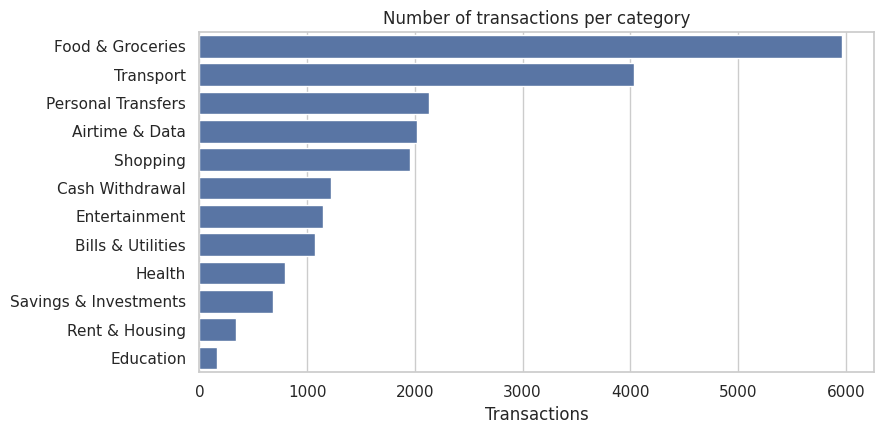

label
Food & Groceries         27.7
Transport                18.7
Personal Transfers        9.9
Airtime & Data            9.4
Shopping                  9.1
Cash Withdrawal           5.7
Entertainment             5.3
Bills & Utilities         5.0
Health                    3.7
Savings & Investments     3.2
Rent & Housing            1.6
Education                 0.8

Most common (Food & Groceries) vs least common (Education): 36x more frequent


In [ ]:
counts = model_df["label"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=counts.values, y=counts.index, color="#4C72B0", ax=ax)
ax.set_title("Number of transactions per category"); ax.set_xlabel("Transactions"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
share = (counts / counts.sum() * 100).round(1)
print(share.to_string())
print(f"\nMost common ({counts.index[0]}) vs least common ({counts.index[-1]}): {counts.iloc[0] / counts.iloc[-1]:.0f}x more frequent")

**Observation 1:** A few categories (Food & Groceries, Transport, Personal Transfers) make up most of the data, while Education, Health and Rent are rare. A model that only learns the big categories would still score high *accuracy*, so we must judge it with **macro F1** (average per category) and use `class_weight="balanced"` so the small categories are not ignored.

### Observation 2: Amounts differ a lot between categories

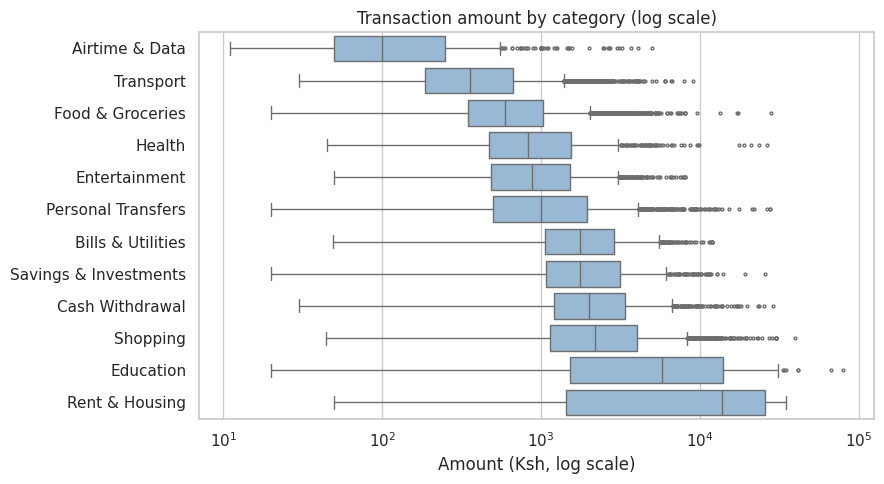

label
Airtime & Data             100.0
Transport                  356.0
Food & Groceries           593.0
Health                     827.0
Entertainment              872.0
Personal Transfers        1000.0
Bills & Utilities         1747.0
Savings & Investments     1770.0
Cash Withdrawal           2000.0
Shopping                  2180.0
Education                 5751.0
Rent & Housing           13700.0


In [ ]:
order = model_df.groupby("label")["amount"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=model_df, x="amount", y="label", order=order, color="#8FB8DE", fliersize=2, ax=ax)
ax.set_xscale("log"); ax.set_title("Transaction amount by category (log scale)"); ax.set_xlabel("Amount (Ksh, log scale)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(model_df.groupby("label")["amount"].median().sort_values().round(0).to_string())

**Observation 2:** Amounts differ enormously between categories. In our data the median Rent payment is over Ksh 13,000 and Education over Ksh 5,000, while the median Airtime top-up is about Ksh 100, Transport about Ksh 350 and Food about Ksh 600. Amount alone does not decide the category, because the ranges overlap (e.g. Shopping, Cash Withdrawal, Bills and Savings all sit around Ksh 1,700-2,200), but it is a strong clue, and the spread is huge. That is why we use `log_amount` instead of the raw amount.

### Observation 3: *When* someone spends reveals what they spend on

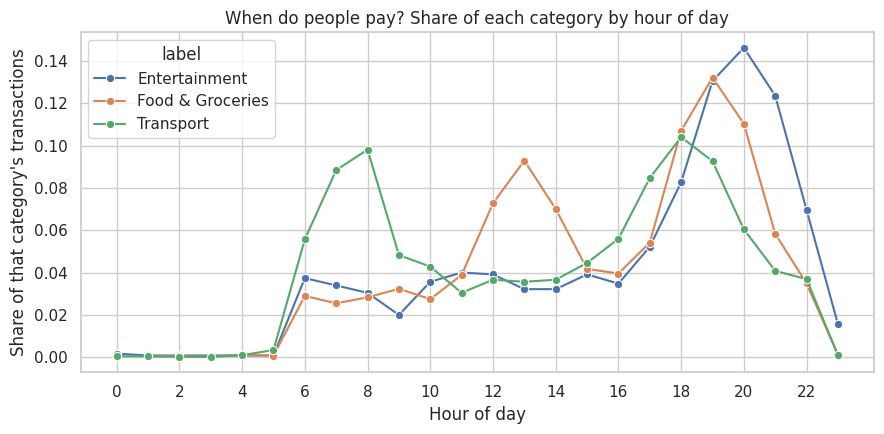

Transport: busiest hours = [8, 18]
Food & Groceries: busiest hours = [19, 20]
Entertainment: busiest hours = [19, 20]


In [ ]:
focus = ["Transport", "Food & Groceries", "Entertainment"]
hour_share = (model_df[model_df["label"].isin(focus)].groupby(["label", "hour"]).size()
              .groupby(level=0).transform(lambda s: s / s.sum()).rename("share").reset_index())
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=hour_share, x="hour", y="share", hue="label", marker="o", ax=ax)
ax.set_xticks(range(0, 24, 2)); ax.set_title("When do people pay? Share of each category by hour of day")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Share of that category's transactions")
plt.tight_layout(); plt.show()
for c in focus:
    top = model_df[model_df["label"] == c]["hour"].value_counts().head(2).index.tolist()
    print(f"{c}: busiest hours = {sorted(top)}")

**Observation 3:** The chart shows three different daily rhythms. Transport has two commute peaks (around 8am and 6pm). Food has a lunchtime bump (around 1pm) and an evening peak (around 7pm). Entertainment is quiet until the evening and peaks latest (around 8pm). So the *hour* helps separate categories whose amounts overlap, but only partly (Food and Entertainment still overlap in the evening), which is why we include `hour_sin` and `hour_cos` *alongside* the merchant name rather than on their own.

### Observation 4: Some categories follow the calendar

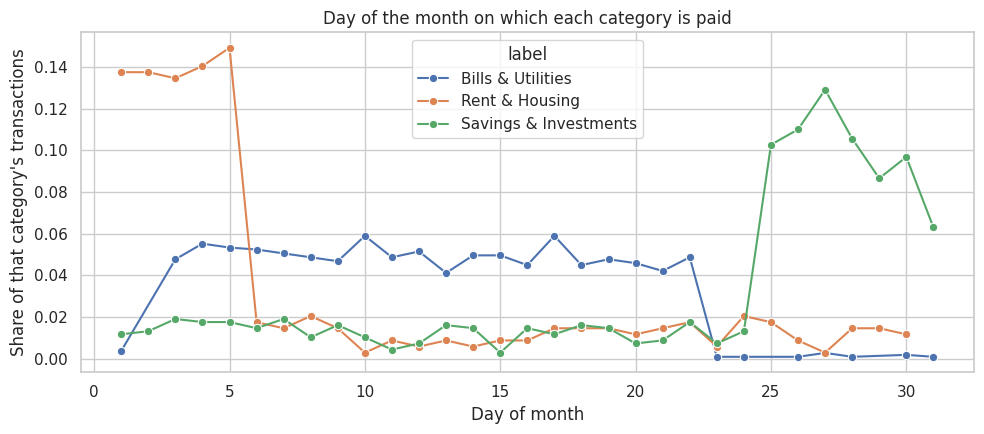

Rent paid on days 1-5:        70%
Savings paid on days 25-31:   69%
Overall share of all spending on days 1-5: 18%


In [ ]:
cal = model_df[model_df["label"].isin(["Rent & Housing", "Savings & Investments", "Bills & Utilities"])]
day_share = (cal.groupby(["label", "day"]).size().groupby(level=0).transform(lambda s: s / s.sum()).rename("share").reset_index())
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=day_share, x="day", y="share", hue="label", marker="o", ax=ax)
ax.set_title("Day of the month on which each category is paid"); ax.set_xlabel("Day of month"); ax.set_ylabel("Share of that category's transactions")
plt.tight_layout(); plt.show()
rent = model_df[model_df["label"] == "Rent & Housing"]
sav  = model_df[model_df["label"] == "Savings & Investments"]
print(f"Rent paid on days 1-5:        {rent['is_month_start'].mean():.0%}")
print(f"Savings paid on days 25-31:   {sav['is_month_end'].mean():.0%}")
print(f"Overall share of all spending on days 1-5: {model_df['is_month_start'].mean():.0%}")

**Observation 4:** Most rent payments (about 70%) fall in the first five days of the month, and most savings contributions (also about 70%) come at the end of the month, just after pay day. Across all spending only about 18% of transactions fall in days 1-5, so the day of the month is real signal. That is why we added `is_month_start` and `is_month_end`.

### Observation 5: The *type* of M-Pesa payment narrows the category, but not completely

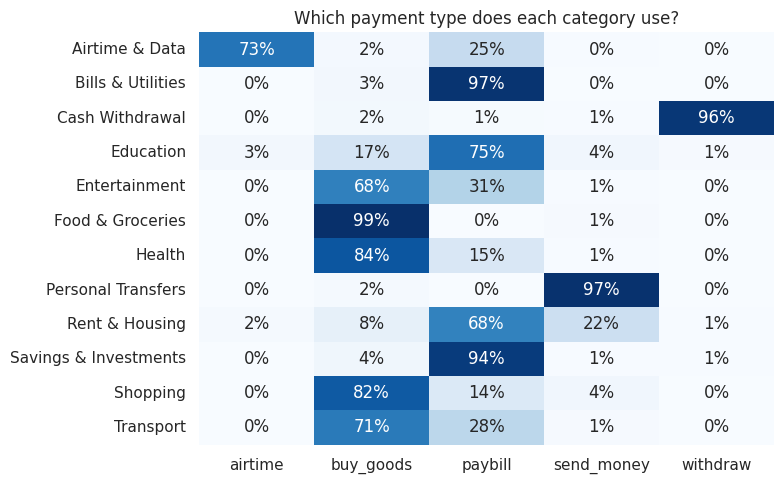

,avg_fee,share_with_fee
txn_type,,
airtime,0.00,0.00
buy_goods,0.00,0.00
paybill,0.00,0.00
send_money,24.95,0.98
withdraw,47.45,1.00


Total fees = 0.34% of all money spent


In [ ]:
ct = pd.crosstab(model_df["label"], model_df["txn_type"], normalize="index")
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Which payment type does each category use?"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

fee_by_type = model_df.groupby("txn_type").agg(avg_fee=("fee", "mean"), share_with_fee=("has_fee", "mean"))
display(fee_by_type.round(2))
print(f"Total fees = {model_df['fee'].sum() / model_df['amount'].sum():.2%} of all money spent")

**Observation 5:** Airtime, Cash Withdrawal and Personal Transfers each use their own payment type, so those are easy. But Food, Shopping, Health and Entertainment all mostly use **buy goods**, so for those the model must rely on the **merchant name**, the amount and the time. Also, only send-money and withdrawals carry fees, so `has_fee` helps identify them.

**EDA takeaway for modelling:** the merchant name matters most, then the amount (log), the time of day and the day of the month. Because the classes are imbalanced, we judge the model on macro F1.

## 4. Base model: Logistic Regression

### Why Logistic Regression?
- It is a standard first model for multi-class classification with text features.
- It is fast, which suits a mobile-app workflow (small model, instant prediction).
- It gives probabilities, so the app can say "90% sure this is Transport" and ask the user to confirm when the model is unsure.
- It has a built-in **regularisation** knob (`C`) that stops it memorising the training data.

### The modelling steps
1. **Hold out a test set** (20%) that the model never sees while we tune it.
2. **Baseline:** a model that always guesses the most common category; our model must beat it.
3. **Build a pipeline** (feature preparation + model in one object, so the same steps apply to training and to the app's new messages).
4. **Tune regularisation with 5-fold cross-validation:** the training data is split into 5 parts; train on 4, check on the 5th, rotate, and average. This gives a more honest score than a single split.
5. **Evaluate once on the held-out test set**, and look at *where* it makes mistakes.

> **Run time:** the whole notebook takes roughly 3 minutes, mostly the Random Forest comparison in Section 5.

In [ ]:
TEXT = "merchant_clean"
CAT  = ["txn_type"]
NUM  = ["log_amount", "hour_sin", "hour_cos", "is_weekend", "is_month_start", "is_month_end", "has_fee"]

X = model_df[[TEXT] + CAT + NUM]
y = model_df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

def make_preprocessor(scaler=None):
    return ColumnTransformer([
        ("text", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True), TEXT),
        ("cat",  OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num",  scaler or StandardScaler(), NUM),
    ])

# ----- baseline: always predict the most common category -----
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_d = dummy.predict(X_test)
print(f"\nBaseline  accuracy: {accuracy_score(y_test, pred_d):.3f} | macro F1: {f1_score(y_test, pred_d, average='macro'):.3f}")

Train: (17225, 9) | Test: (4307, 9)

Baseline  accuracy: 0.277 | macro F1: 0.036


### Tuning regularisation with cross-validation
`C` controls how strictly the model is held back from overfitting: **small C = strong regularisation** (simpler model), **large C = weak regularisation** (can memorise). We try several values and let 5-fold cross-validation pick the best one. We also record the *training* score: if it is far above the validation score, the model is overfitting.

,C,train_macroF1,validation_macroF1,validation_std
0,0.01,0.8619,0.8567,0.0086
1,0.10,0.9311,0.9306,0.0022
2,1.00,0.9302,0.9299,0.0019
3,10.00,0.9289,0.9283,0.0020
4,100.00,0.9286,0.9280,0.0022


Best C = 0.1 | cross-validated macro F1 = 0.9306


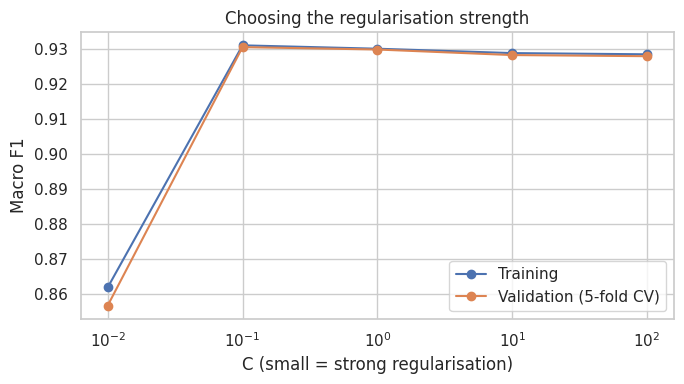

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe = Pipeline([("prep", make_preprocessor()),
                 ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])

grid = GridSearchCV(pipe, param_grid={"clf__C": [0.01, 0.1, 1, 10, 100]}, cv=cv,
                    scoring="f1_macro", n_jobs=-1, return_train_score=True, refit=True)
grid.fit(X_train, y_train)

res = pd.DataFrame({"C": grid.cv_results_["param_clf__C"].astype(float),
                    "train_macroF1": grid.cv_results_["mean_train_score"],
                    "validation_macroF1": grid.cv_results_["mean_test_score"],
                    "validation_std": grid.cv_results_["std_test_score"]})
display(res.round(4))
print(f"Best C = {grid.best_params_['clf__C']} | cross-validated macro F1 = {grid.best_score_:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(res["C"], res["train_macroF1"], "o-", label="Training")
ax.plot(res["C"], res["validation_macroF1"], "o-", label="Validation (5-fold CV)")
ax.set_xscale("log"); ax.set_xlabel("C (small = strong regularisation)"); ax.set_ylabel("Macro F1")
ax.set_title("Choosing the regularisation strength"); ax.legend()
plt.tight_layout(); plt.show()

**Reading the chart:** with very strong regularisation (`C = 0.01`) the model is too simple and both scores are low (underfitting). From `C = 0.1` upward the scores level off and even dip slightly. The training and validation scores stay very close to each other, so there is no sign of overfitting. We keep the `C` with the best validation score (`best_estimator_`), which is also the simpler of the near-equal options.

### Final check on the held-out test set
The test set was not used for any tuning, so this is our honest estimate of performance on new messages.

Test accuracy: 0.950 | Test macro F1: 0.917
(Baseline was accuracy 0.277 | macro F1 0.036)

                       precision    recall  f1-score   support

       Airtime & Data      0.980     0.953     0.966       404
    Bills & Utilities      0.958     0.953     0.956       214
      Cash Withdrawal      0.975     0.963     0.969       244
            Education      1.000     0.576     0.731        33
        Entertainment      0.965     0.970     0.967       230
     Food & Groceries      0.980     0.951     0.966      1193
               Health      0.993     0.950     0.971       159
   Personal Transfers      0.848     0.986     0.912       426
       Rent & Housing      1.000     0.588     0.741        68
Savings & Investments      0.962     0.934     0.948       136
             Shopping      0.877     0.944     0.909       392
            Transport      0.965     0.969     0.967       808

             accuracy                          0.950      4307
            macro avg   

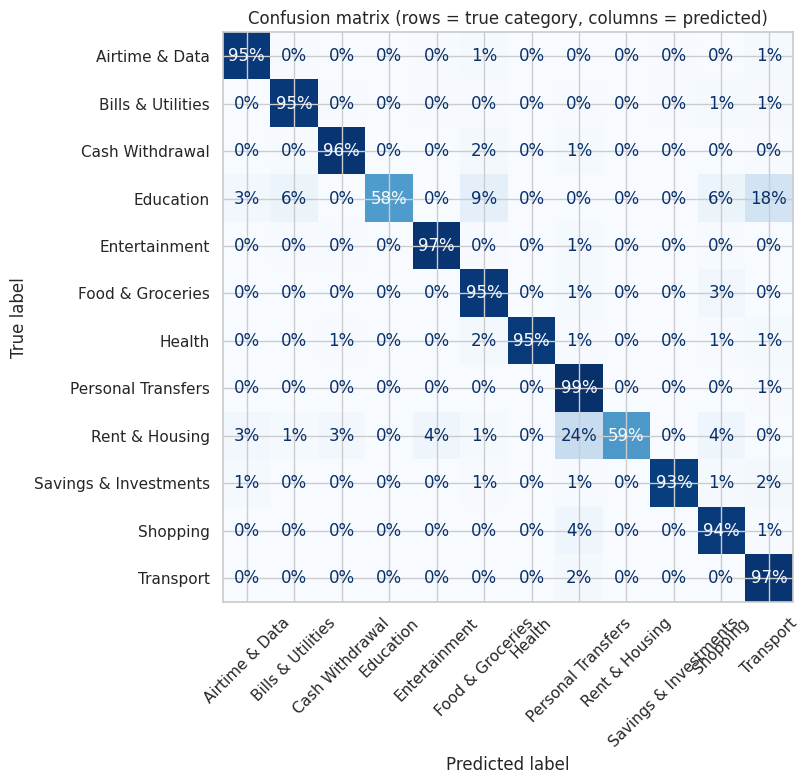

In [ ]:
best = grid.best_estimator_
y_pred = best.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f} | Test macro F1: {f1_score(y_test, y_pred, average='macro'):.3f}")
print(f"(Baseline was accuracy {accuracy_score(y_test, pred_d):.3f} | macro F1 {f1_score(y_test, pred_d, average='macro'):.3f})\n")
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", xticks_rotation=45, cmap="Blues",
                                        values_format=".0%", colorbar=False, ax=ax)
ax.set_title("Confusion matrix (rows = true category, columns = predicted)")
plt.tight_layout(); plt.show()

### Error analysis: where does the model get it wrong?

In [ ]:
errors = X_test.copy()
errors["true"], errors["predicted"] = y_test, y_pred
errors["amount"] = model_df.loc[errors.index, "amount"]
wrong = errors[errors["true"] != errors["predicted"]]
print(f"{len(wrong)} wrong out of {len(errors)} test transactions ({len(wrong)/len(errors):.1%})")
print("\nMost common confusions (true -> predicted):")
print(wrong.groupby(["true", "predicted"]).size().sort_values(ascending=False).head(6).to_string())
display(wrong[["merchant_clean", "txn_type", "amount", "true", "predicted"]].head(8))

215 wrong out of 4307 test transactions (5.0%)

Most common confusions (true -> predicted):
true              predicted         
Food & Groceries  Shopping              37
Transport         Personal Transfers    17
Shopping          Personal Transfers    16
Rent & Housing    Personal Transfers    16
Food & Groceries  Personal Transfers    16
Education         Transport              6


,merchant_clean,txn_type,amount,true,predicted
16164,BOLT KENYA,paybill,438.0,Education,Transport
6784,SHELL KAREN,buy_goods,662.0,Education,Transport
20847,PERSON,send_money,2650.0,Food & Groceries,Personal Transfers
3507,MWANGI TRADERS,buy_goods,460.0,Food & Groceries,Shopping
5239,PERSON,send_money,900.0,Transport,Personal Transfers
2032,PERSON,send_money,200.0,Transport,Personal Transfers
6395,PERSON,send_money,600.0,Shopping,Personal Transfers
16483,JEPTOO ENTERPRISES,buy_goods,530.0,Food & Groceries,Shopping


**Reading the mistakes:** the errors fall into three groups.
1. **Ambiguous shops** (`... ENTERPRISES`, `... TRADERS`) are confused between Food and Shopping, which is understandable because the name does not say what they sell.
2. **Person-to-person transfers** are confused with other categories. A transfer to a person could be rent, food money or a fare, and the message cannot tell us which.
3. **Noisy labels.** Education and Rent show perfect precision but low recall. Looking at the examples, many "Education" rows are Bolt or Shell payments that our simulated users mislabelled, and the model is arguably *right* to disagree. Rare categories suffer most from this, because a handful of wrong labels is a big share of a small class.

These are the cases where the app should **ask the user** rather than guess (see Section 6).

## 5. Further validation (Question 4)

The brief asks us to determine **other methods to validate the base model**. Our plan is to build other models using the *same process* (same cleaned data, same features, same split, same 5-fold CV) and compare them with the base model. If several different algorithms reach similar scores, we can trust that the result comes from the data and features, not from luck or a quirk of one algorithm.

| Validation method | What it checks | Status |
|---|---|---|
| **Model comparison** (Logistic Regression vs Linear SVM vs Random Forest vs Naive Bayes) | Is the result stable across different algorithms? | Run below |
| **Group-aware CV** (keep each user's messages together) | Does it work for a *new user* it has never seen? | Run below |
| Hold-out on **unseen merchants** | Does it generalise to shops not in the training data? | Planned |
| Learning curve | Would more data help? | Planned |
| Test on **real, consented user data** | Does synthetic performance carry over to reality? | Planned (required before launch) |

,model,accuracy,macro_F1,macroF1_std,fit_seconds
0,Logistic Regression (base),0.9558,0.9306,0.0022,2.8097
1,Linear SVM,0.9551,0.9304,0.0017,4.7469
2,Complement Naive Bayes,0.9551,0.9304,0.0017,0.4134
3,Random Forest,0.9457,0.9145,0.0061,19.2975


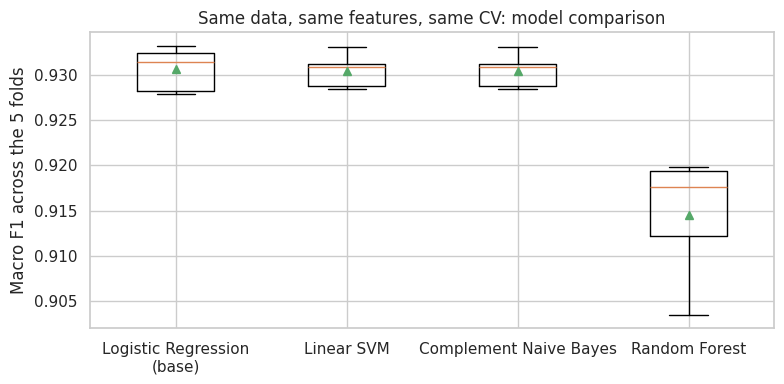

In [ ]:
def make_pipe(clf, scaler=None):
    return Pipeline([("prep", make_preprocessor(scaler)), ("clf", clf)])

best_C = grid.best_params_["clf__C"]
models = {
    "Logistic Regression (base)": make_pipe(LogisticRegression(C=best_C, max_iter=2000, class_weight="balanced")),
    "Linear SVM":                 make_pipe(LinearSVC(C=0.1, class_weight="balanced", max_iter=5000)),
    "Complement Naive Bayes":     make_pipe(ComplementNB(), scaler=MinMaxScaler()),   # NB cannot take negative numbers
    "Random Forest":              make_pipe(RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
}

rows, fold_scores = [], {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=1)
    fold_scores[name] = r["test_f1_macro"]
    rows.append(dict(model=name, accuracy=r["test_accuracy"].mean(), macro_F1=r["test_f1_macro"].mean(),
                     macroF1_std=r["test_f1_macro"].std(), fit_seconds=r["fit_time"].mean()))
comparison = pd.DataFrame(rows).sort_values("macro_F1", ascending=False)
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(list(fold_scores.values()), labels=[n.replace(" (base)", "\n(base)") for n in fold_scores], showmeans=True)
ax.set_ylabel("Macro F1 across the 5 folds"); ax.set_title("Same data, same features, same CV: model comparison")
plt.tight_layout(); plt.show()

In [ ]:
# ----- Group-aware validation: can the model handle a user it has never seen? -----
groups = model_df.loc[X_train.index, "user_id"]
gkf = GroupKFold(n_splits=5)
g_scores = cross_val_score(make_pipe(LogisticRegression(C=best_C, max_iter=2000, class_weight="balanced")),
                           X_train, y_train, cv=gkf, groups=groups, scoring="f1_macro", n_jobs=-1)
print(f"Stratified 5-fold CV macro F1 : {grid.best_score_:.4f}")
print(f"Group (by user) 5-fold CV     : {g_scores.mean():.4f}  (+/- {g_scores.std():.4f})")

Stratified 5-fold CV macro F1 : 0.9306
Group (by user) 5-fold CV     : 0.9273  (+/- 0.0118)


**Reading Section 5:**
- Logistic Regression, Linear SVM and Naive Bayes score almost the same, and Random Forest is slightly lower and much slower to train. Different algorithms agreeing suggests the result comes from the data and features, not from a quirk of Logistic Regression. It also supports keeping the simple, fast, small model for the mobile app.
- The group-aware score is close to the normal CV score, so the model is not just memorising individual users' habits. A big drop there would mean it fails on new users, which would matter a lot for a real app.
- These results come from synthetic data, where merchant names map fairly cleanly to categories, so real data will probably score lower. (Exact numbers can shift slightly between runs and library versions. Re-read the tables rather than relying on figures quoted here.)

## 6. What the app will do with a brand-new SMS

This is the end-to-end flow the mobile app will follow: raw SMS text → parse → clean → features → predict. When the model is not confident, the app should ask the user to confirm the category. That confirmation becomes a new labelled example for retraining.

In [ ]:
joblib.dump(best, "models/expense_classifier_logreg.joblib")
print("Saved: models/expense_classifier_logreg.joblib")

def predict_sms(text, top_k=3, confidence_threshold=0.6):
    p = parse_sms(text)
    if p["txn_type"] is None or p["txn_type"] == "received" or p["date_str"] is None:
        return "Not an expense message the model can categorise."
    row = pd.DataFrame([{
        "txn_type": p["txn_type"], "merchant_clean": clean_party(p["txn_type"], p["party"]), "amount": p["amount"],
        "fee": p["fee"] if not np.isnan(p["fee"]) else fee_median.get(p["txn_type"], 0.0),
        "timestamp": pd.to_datetime(p["date_str"] + " " + p["time_str"], format="%d/%m/%y %I:%M %p"),
    }])
    row = add_features(row)[[TEXT] + CAT + NUM]
    proba = best.predict_proba(row)[0]
    top = np.argsort(proba)[::-1][:top_k]
    suggestions = [(best.classes_[i], round(float(proba[i]), 2)) for i in top]
    status = "auto-categorise" if proba[top[0]] >= confidence_threshold else "ASK THE USER TO CONFIRM"
    return {"merchant": row.loc[0, TEXT], "amount": p["amount"], "suggestions": suggestions, "app_action": status}

demo = [
    "QAB1C2D3E4 Confirmed. Ksh1,250.00 paid to NAIVAS SUPERMARKET. on 17/10/26 at 6:45 PM.New M-PESA balance is Ksh3,400.00. Transaction cost, Ksh0.00.",
    "QXY9Z8W7V6 Confirmed. Ksh15,000.00 sent to KILIMANI APARTMENTS LTD for account B12 on 2/10/26 at 8:10 AM New M-PESA balance is Ksh9,000.00. Transaction cost, Ksh0.00.",
    "QMN4P5R6S7 Confirmed. Ksh800.00 paid to WAMBUI ENTERPRISES. on 12/10/26 at 1:20 PM.New M-PESA balance is Ksh1,200.00. Transaction cost, Ksh0.00.",
]
for s in demo:
    print(predict_sms(s), "\n")

Saved: models/expense_classifier_logreg.joblib
{'merchant': 'NAIVAS SUPERMARKET', 'amount': 1250.0, 'suggestions': [('Food & Groceries', 0.66), ('Education', 0.1), ('Shopping', 0.06)], 'app_action': 'auto-categorise'} 

{'merchant': 'KILIMANI APARTMENTS', 'amount': 15000.0, 'suggestions': [('Rent & Housing', 0.93), ('Education', 0.02), ('Savings & Investments', 0.01)], 'app_action': 'auto-categorise'} 

{'merchant': 'WAMBUI ENTERPRISES', 'amount': 800.0, 'suggestions': [('Shopping', 0.54), ('Food & Groceries', 0.2), ('Health', 0.08)], 'app_action': 'ASK THE USER TO CONFIRM'} 



## 7. Limitations and next steps

**Limitations (be honest about these in the presentation):**
- **The data is synthetic.** Merchant names map cleanly to categories, so real-world scores will be lower. The workflow is what we are demonstrating.
- **Labels in the real app come from users**, who are inconsistent. We simulated this with a few percent of label noise.
- **Class imbalance:** rare categories (Education, Health) have fewer examples and weaker scores.
- **Cold start:** a brand-new merchant with an unfamiliar name is harder; the character n-grams help, but not always.
- **Privacy:** real SMS data is sensitive. In the real app, names and phone numbers are stripped before modelling (as in Section 2.7), processing should happen on the device or with consent, and real messages must never be committed to GitHub.

**Next steps:**
1. Collect a small amount of real, consented, anonymised M-Pesa data and re-run this notebook on it.
2. Finish the validation plan in Section 5 (unseen merchants, learning curve).
3. Add per-user personalisation (the same user usually puts the same merchant in the same category).
4. Decide how the model reaches the mobile app: an on-device model or a small API.
5. Let user corrections flow back as new labelled data and retrain periodically.